In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from itertools import combinations

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

from scipy.stats import spearmanr

import shap
from lime.lime_tabular import LimeTabularExplainer

out_dir = "xai_outputs_stroke"
os.makedirs(out_dir, exist_ok=True)

# -----------------------------
# 1. Load and preprocess exactly as replication
# -----------------------------
file_path = "../../data/stroke/healthcare-dataset-stroke-data.csv"
df = pd.read_csv(file_path)

df = df[df['gender'] != 'Other'].copy()
df['age'] = df['age'].astype(int)

df['bmi_missing'] = df['bmi'].isna().astype(int)
df['bmi'] = df['bmi'].fillna(df['bmi'].mean())

df = df.drop('id', axis=1)

categorical_cols = [
    'gender',
    'smoking_status',
    'Residence_type',
    'work_type',
    'ever_married'
]

df = pd.get_dummies(df, columns=categorical_cols, drop_first=False)

X_full = df.drop('stroke', axis=1)
y = df['stroke']

corr = df.corr()['stroke'].abs()
selected_features = corr[corr > 0.1].index
selected_features = [c for c in selected_features if c != "stroke"]

X_selected = df[selected_features].copy()

print("Selected features:")
print(selected_features)

# -----------------------------
# 2. Train-test split
# -----------------------------
X_train_sel, X_test_sel, y_train, y_test = train_test_split(
    X_selected, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

feature_names = X_train_sel.columns.tolist()

scaler_sel = StandardScaler()
X_train_sel_scaled = scaler_sel.fit_transform(X_train_sel)
X_test_sel_scaled = scaler_sel.transform(X_test_sel)

X_train_sel_scaled_df = pd.DataFrame(X_train_sel_scaled, columns=feature_names, index=X_train_sel.index)
X_test_sel_scaled_df = pd.DataFrame(X_test_sel_scaled, columns=feature_names, index=X_test_sel.index)

# -----------------------------
# 3. Final explained model
# -----------------------------
final_model = LogisticRegression(max_iter=1000)
final_model.fit(X_train_sel_scaled_df, y_train)

y_pred = final_model.predict(X_test_sel_scaled_df)
y_prob = final_model.predict_proba(X_test_sel_scaled_df)[:, 1]

print("Final XAI model: Logistic Regression on selected features")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1       :", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("AUC      :", round(roc_auc_score(y_test, y_prob), 4))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))


c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Selected features:
['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi_missing', 'ever_married_No', 'ever_married_Yes']
Final XAI model: Logistic Regression on selected features
Accuracy : 0.9501
Precision: 0.3333
Recall   : 0.02
F1       : 0.0377
AUC      : 0.8338

Confusion matrix:
[[970   2]
 [ 49   1]]



Logistic regression coefficients
             Feature  Coefficient  AbsCoefficient
0                age       1.5489          1.5489
4        bmi_missing       0.2901          0.2901
3  avg_glucose_level       0.1824          0.1824
1       hypertension       0.1328          0.1328
5    ever_married_No       0.0604          0.0604
6   ever_married_Yes      -0.0604          0.0604
2      heart_disease       0.0204          0.0204


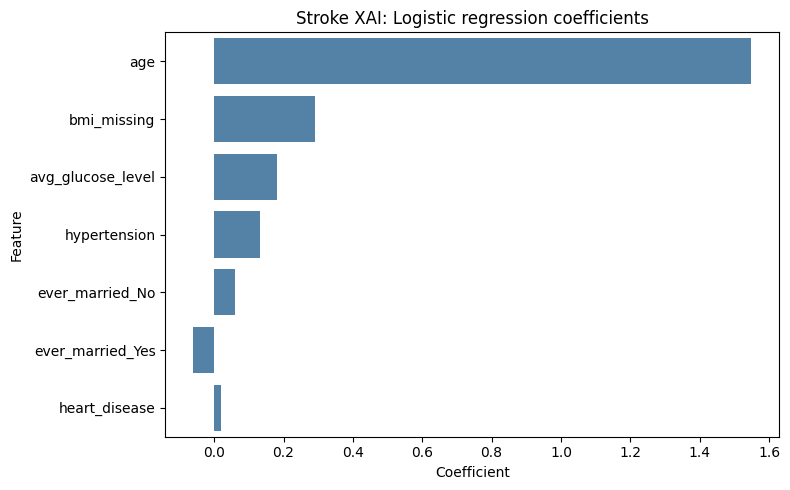


Permutation importance
             Feature  PermutationMean  PermutationStd
0                age           0.3134          0.0308
3  avg_glucose_level           0.0050          0.0039
4        bmi_missing           0.0031          0.0029
2      heart_disease           0.0007          0.0004
5    ever_married_No          -0.0004          0.0012
6   ever_married_Yes          -0.0004          0.0012
1       hypertension          -0.0005          0.0022


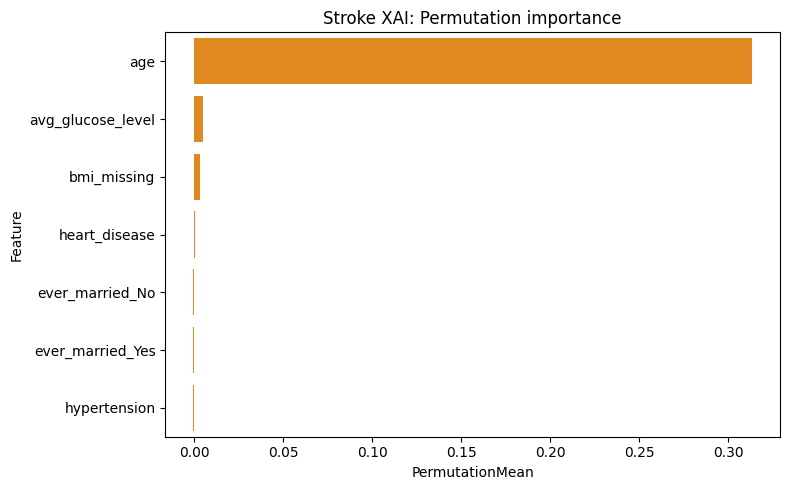

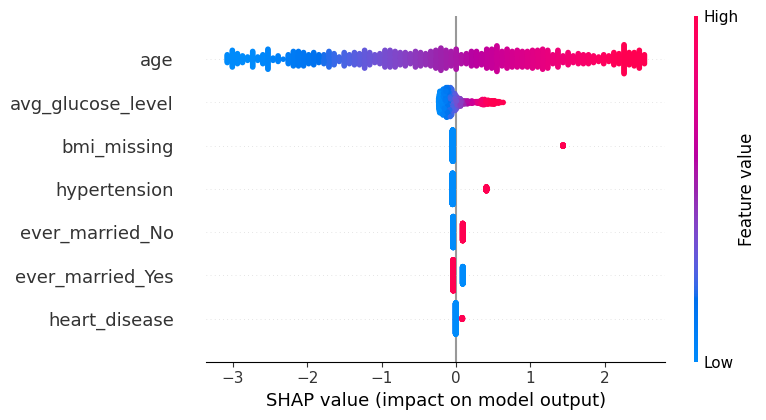

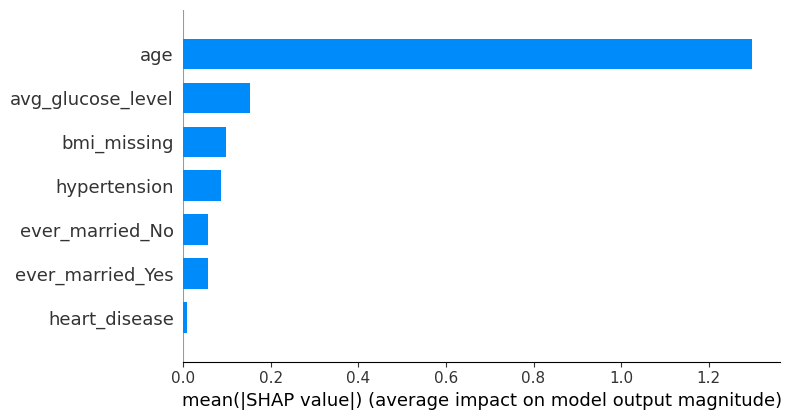


SHAP importance
             Feature  MeanAbsSHAP
0                age       1.2985
3  avg_glucose_level       0.1523
4        bmi_missing       0.0963
1       hypertension       0.0848
5    ever_married_No       0.0562
6   ever_married_Yes       0.0562
2      heart_disease       0.0070


In [2]:
# -----------------------------
# 4. Global XAI: coefficients
# -----------------------------
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": final_model.coef_[0],
    "AbsCoefficient": np.abs(final_model.coef_[0])
}).sort_values("AbsCoefficient", ascending=False)

print("\nLogistic regression coefficients")
print(coef_df.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(data=coef_df, x="Coefficient", y="Feature", color="steelblue")
plt.title("Stroke XAI: Logistic regression coefficients")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "stroke_lr_coefficients.png"), dpi=300)
plt.show()

# -----------------------------
# 5. Global XAI: permutation importance
# -----------------------------
perm = permutation_importance(
    final_model,
    X_test_sel_scaled_df,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring="roc_auc"
)

perm_df = pd.DataFrame({
    "Feature": feature_names,
    "PermutationMean": perm.importances_mean,
    "PermutationStd": perm.importances_std
}).sort_values("PermutationMean", ascending=False)

print("\nPermutation importance")
print(perm_df.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(data=perm_df, x="PermutationMean", y="Feature", color="darkorange")
plt.title("Stroke XAI: Permutation importance")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "stroke_permutation_importance.png"), dpi=300)
plt.show()

# -----------------------------
# 6. Global XAI: SHAP
# -----------------------------
explainer = shap.LinearExplainer(final_model, X_train_sel_scaled_df)
shap_values = explainer.shap_values(X_test_sel_scaled_df)

shap_values = np.array(shap_values)
if shap_values.ndim == 3:
    shap_plot_values = shap_values[:, :, 1]
else:
    shap_plot_values = shap_values

shap.summary_plot(shap_plot_values, X_test_sel_scaled_df, show=False)
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "stroke_shap_summary.png"), dpi=300, bbox_inches="tight")
plt.show()

shap.summary_plot(shap_plot_values, X_test_sel_scaled_df, plot_type="bar", show=False)
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "stroke_shap_bar.png"), dpi=300, bbox_inches="tight")
plt.show()

shap_imp = pd.DataFrame({
    "Feature": feature_names,
    "MeanAbsSHAP": np.abs(shap_plot_values).mean(axis=0)
}).sort_values("MeanAbsSHAP", ascending=False)

print("\nSHAP importance")
print(shap_imp.round(4))



Correlation-based selection vs SHAP ranking
             Feature  AbsCorrelation  CorrelationRank  SHAPRank  MeanAbsSHAP
0                age          0.2451                1         1       1.2985
1        bmi_missing          0.1412                2         3       0.0963
2      heart_disease          0.1349                3         7       0.0070
3  avg_glucose_level          0.1320                4         2       0.1523
4       hypertension          0.1279                5         4       0.0848
5   ever_married_Yes          0.1083                6         6       0.0562
6    ever_married_No          0.1083                7         5       0.0562

Spearman correlation: 0.5357 (p=0.2152)


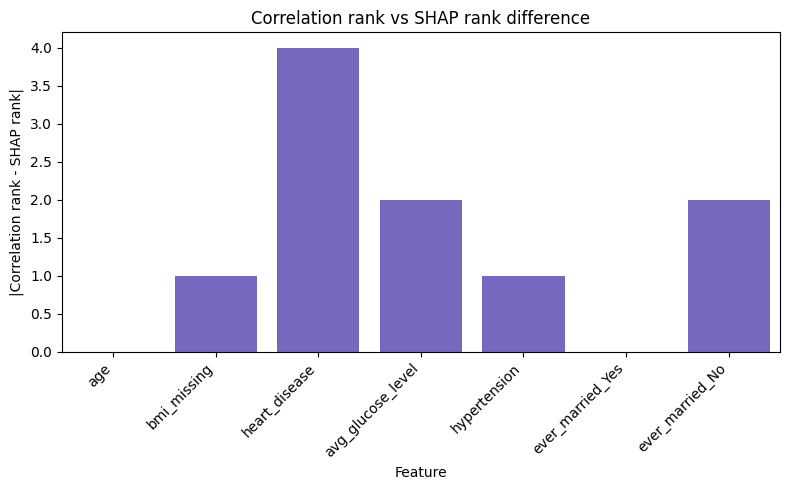

In [3]:
# -----------------------------
# 7. Compare correlation selection vs XAI ranking
# -----------------------------
corr_rank = (
    corr[selected_features]
    .sort_values(ascending=False)
    .reset_index()
)
corr_rank.columns = ["Feature", "AbsCorrelation"]
corr_rank["CorrelationRank"] = np.arange(1, len(corr_rank) + 1)

xai_rank = shap_imp.reset_index(drop=True).copy()
xai_rank["SHAPRank"] = np.arange(1, len(xai_rank) + 1)

rank_compare = corr_rank.merge(
    xai_rank[["Feature", "SHAPRank", "MeanAbsSHAP"]],
    on="Feature",
    how="left"
)

rho_corr_shap, p_corr_shap = spearmanr(
    rank_compare["CorrelationRank"],
    rank_compare["SHAPRank"]
)

print("\nCorrelation-based selection vs SHAP ranking")
print(rank_compare.round(4))
print(f"\nSpearman correlation: {rho_corr_shap:.4f} (p={p_corr_shap:.4f})")

rank_compare["RankDifference"] = (
    rank_compare["CorrelationRank"] - rank_compare["SHAPRank"]
).abs()

plt.figure(figsize=(8, 5))
sns.barplot(
    data=rank_compare.sort_values("CorrelationRank"),
    x="Feature",
    y="RankDifference",
    color="slateblue"
)
plt.title("Correlation rank vs SHAP rank difference")
plt.ylabel("|Correlation rank - SHAP rank|")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "stroke_rank_difference_corr_vs_shap.png"), dpi=300)
plt.show()



Top 3 SHAP features: ['age', 'avg_glucose_level', 'bmi_missing']


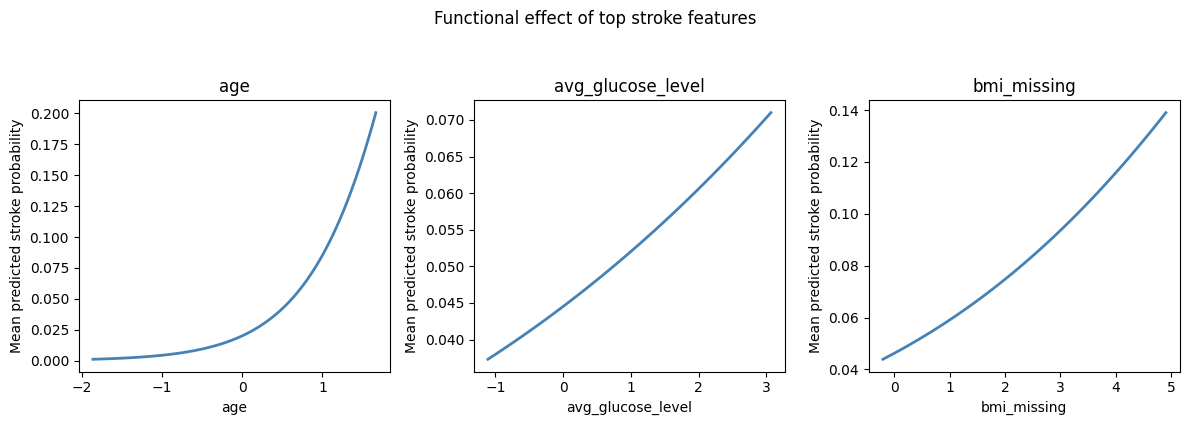


Representative cases
         age  hypertension  heart_disease  avg_glucose_level  bmi_missing  \
13    1.5335       -0.3234         4.0763             2.5507       4.9065   
2875 -1.9084       -0.3234        -0.2453            -1.0184      -0.2038   
4684  1.5335        3.0920         4.0763             2.2528       4.9065   
245  -1.2906       -0.3234        -0.2453            -1.0737      -0.2038   
3162  1.5335        3.0920        -0.2453            -0.3516       4.9065   

      ever_married_No  ever_married_Yes  y_true  y_pred  y_prob  dist_to_05  \
13            -0.7179            0.7179       1       1  0.5492      0.0492   
2875           1.3929           -1.3929       0       0  0.0008      0.4992   
4684          -0.7179            0.7179       0       1  0.6450      0.1450   
245            1.3929           -1.3929       1       0  0.0021      0.4979   
3162          -0.7179            0.7179       0       1  0.5084      0.0084   

        CaseType  
13            TP  
28

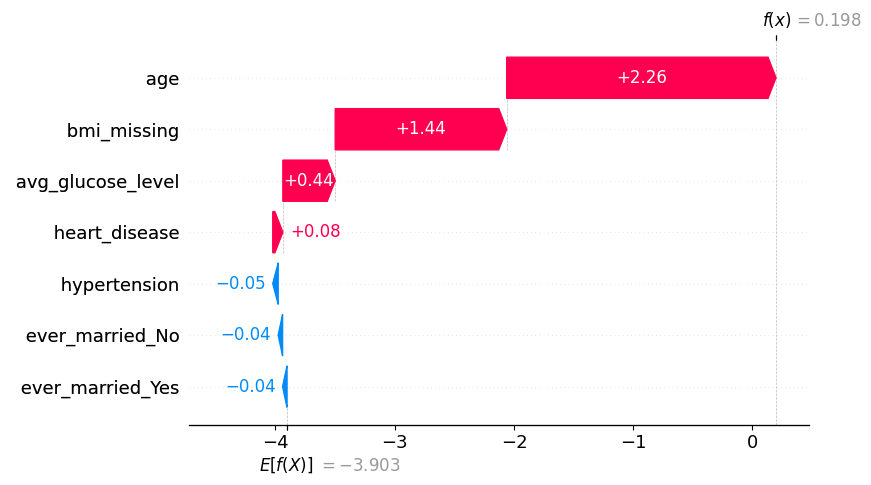

<Figure size 640x480 with 0 Axes>


SHAP local explanation for case 2875
CaseType          TN
y_true             0
y_pred             0
y_prob      0.000824
Name: 2875, dtype: object


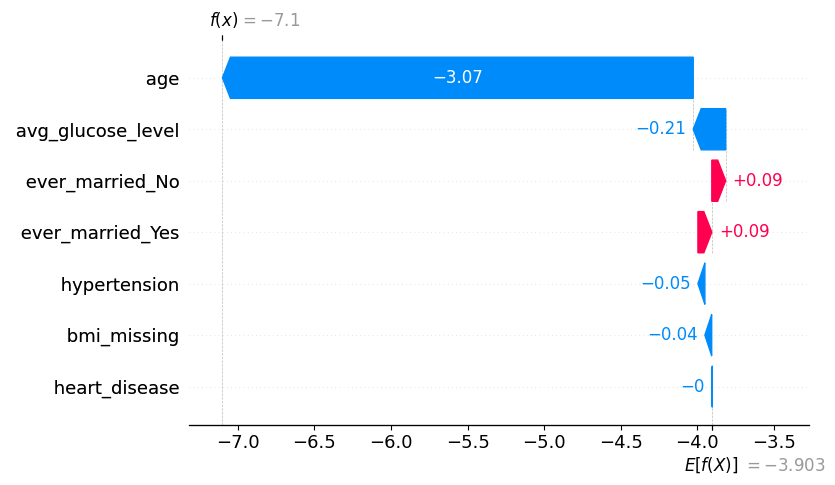

<Figure size 640x480 with 0 Axes>


SHAP local explanation for case 4684
CaseType         FP
y_true            0
y_pred            1
y_prob      0.64495
Name: 4684, dtype: object


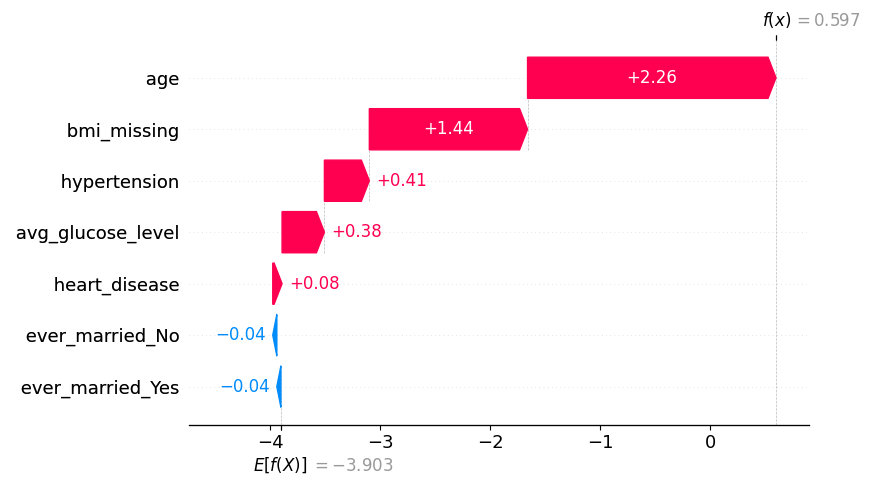

<Figure size 640x480 with 0 Axes>


SHAP local explanation for case 245
CaseType          FN
y_true             1
y_pred             0
y_prob      0.002122
Name: 245, dtype: object


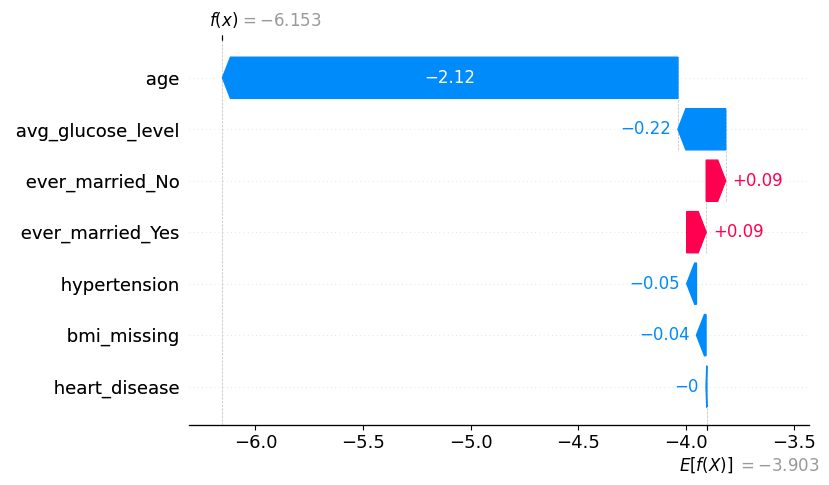

<Figure size 640x480 with 0 Axes>


SHAP local explanation for case 3162
CaseType    Borderline
y_true               0
y_pred               1
y_prob        0.508429
Name: 3162, dtype: object


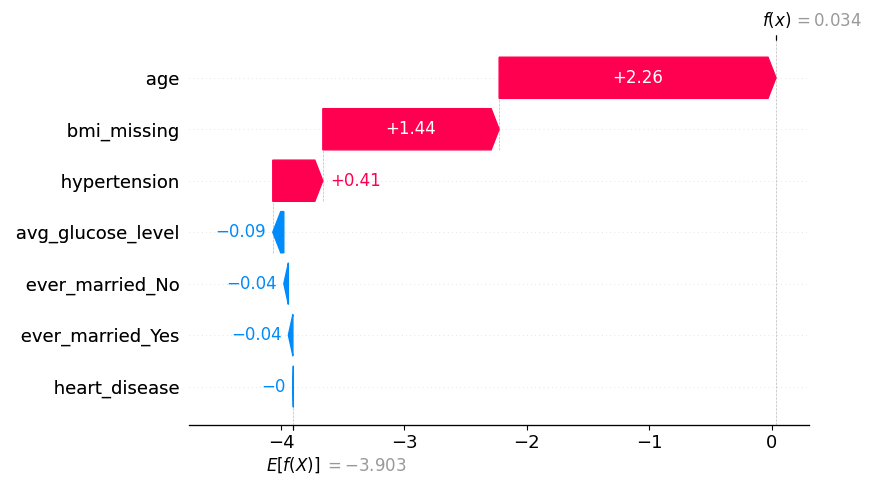

<Figure size 640x480 with 0 Axes>

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(



LIME explanation for case 13
CaseType          TP
y_true             1
y_pred             1
y_prob      0.549227
Name: 13, dtype: object
[('age > 0.78', 0.11516770785061342), ('bmi_missing > -0.20', 0.09198506786961111), ('hypertension <= -0.32', -0.020873381822338662), ('avg_glucose_level > 0.18', 0.018209910466252425), ('heart_disease > -0.25', 0.005454678960611029), ('-1.39 < ever_married_Yes <= 0.72', -0.003695767265177615), ('ever_married_No <= -0.72', -0.0034891650521195945)]


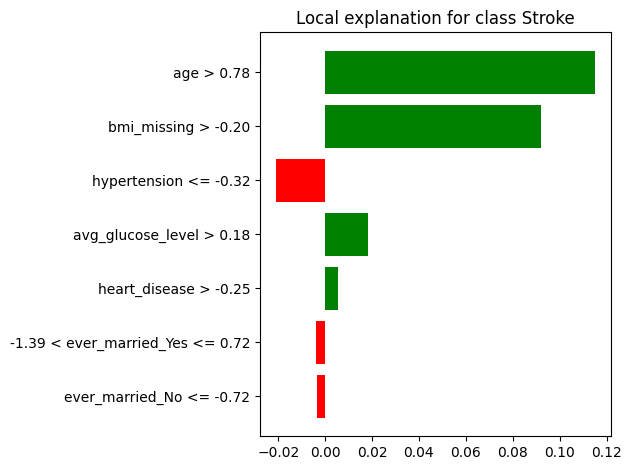

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(



LIME explanation for case 2875
CaseType          TN
y_true             0
y_pred             0
y_prob      0.000824
Name: 2875, dtype: object
[('bmi_missing <= -0.20', -0.09299155723220709), ('age <= -0.81', -0.05900590892596879), ('hypertension <= -0.32', -0.01661919261835316), ('avg_glucose_level <= -0.64', -0.008788987645916086), ('-0.72 < ever_married_No <= 1.39', 0.0029229153507415164), ('ever_married_Yes <= -1.39', 0.0021414952641235388), ('heart_disease <= -0.25', -0.0017069516149085247)]


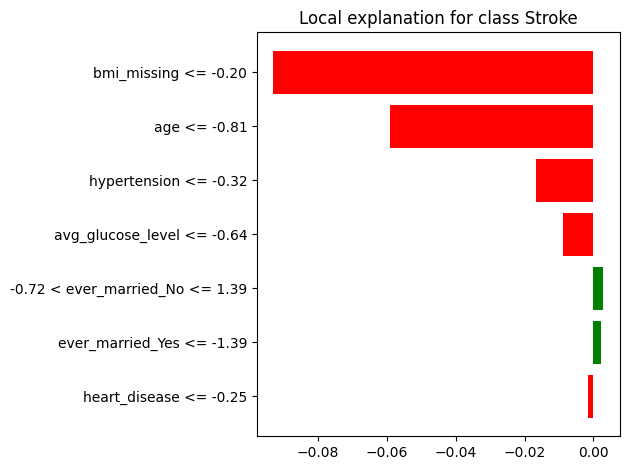

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(



LIME explanation for case 4684
CaseType         FP
y_true            0
y_pred            1
y_prob      0.64495
Name: 4684, dtype: object
[('age > 0.78', 0.11754836000066221), ('bmi_missing > -0.20', 0.10130645081036573), ('hypertension > -0.32', 0.02387078058088191), ('avg_glucose_level > 0.18', 0.01989001910349629), ('heart_disease > -0.25', 0.005974081337056377), ('ever_married_No <= -0.72', -0.004368782065864908), ('-1.39 < ever_married_Yes <= 0.72', -0.0016381304263523079)]


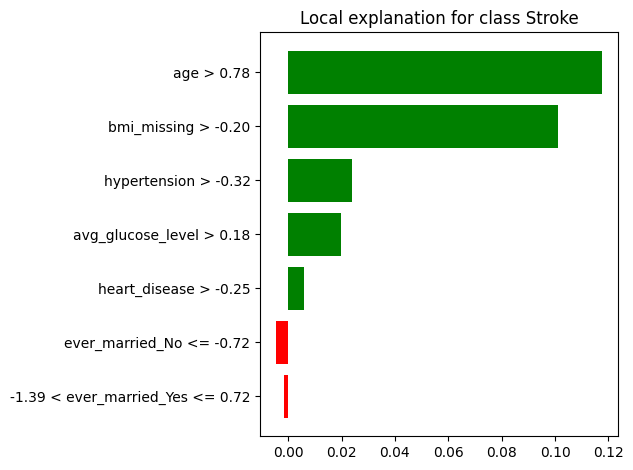

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(



LIME explanation for case 245
CaseType          FN
y_true             1
y_pred             0
y_prob      0.002122
Name: 245, dtype: object
[('bmi_missing <= -0.20', -0.07577884831958816), ('age <= -0.81', -0.057982490664927874), ('hypertension <= -0.32', -0.018482068517519348), ('avg_glucose_level <= -0.64', -0.010600865132313488), ('heart_disease <= -0.25', -0.006619152954499107), ('-0.72 < ever_married_No <= 1.39', 0.002880055770100479), ('ever_married_Yes <= -1.39', 0.0005641215183689331)]


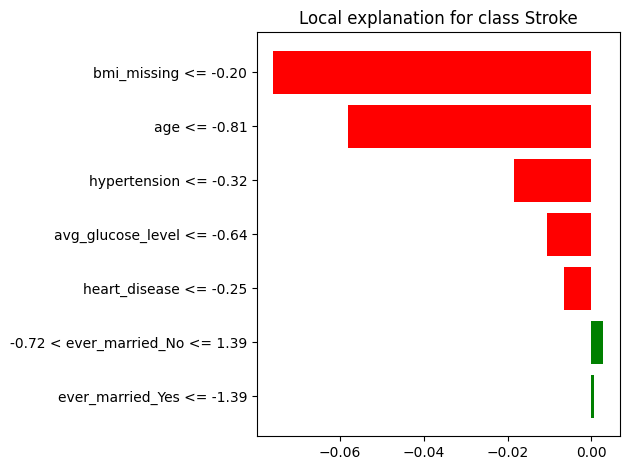

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(



LIME explanation for case 3162
CaseType    Borderline
y_true               0
y_pred               1
y_prob        0.508429
Name: 3162, dtype: object
[('age > 0.78', 0.11515952631666108), ('bmi_missing > -0.20', 0.10677564260914724), ('hypertension > -0.32', 0.021954269418846418), ('heart_disease <= -0.25', -0.007683109677062574), ('-0.64 < avg_glucose_level <= -0.31', -0.0058807524900601855), ('-1.39 < ever_married_Yes <= 0.72', -0.002406359619274553), ('ever_married_No <= -0.72', -0.002116483449486775)]


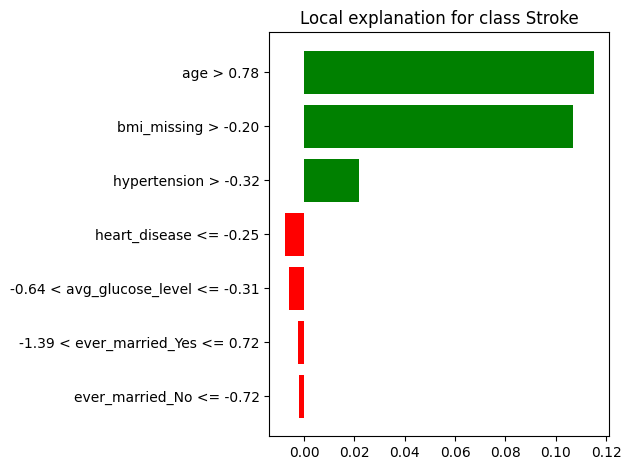

In [5]:
# -----------------------------
# 8. Functional XAI: manual probability profiles
# -----------------------------
top_features = shap_imp["Feature"].head(3).tolist()
print("\nTop 3 SHAP features:", top_features)

fig, axes = plt.subplots(1, len(top_features), figsize=(12, 4))

if len(top_features) == 1:
    axes = [axes]

X_ref = X_test_sel_scaled_df.copy()

for ax, feat in zip(axes, top_features):
    grid = np.linspace(
        X_ref[feat].quantile(0.01),
        X_ref[feat].quantile(0.99),
        80
    )

    mean_probs = []

    for val in grid:
        X_temp = X_ref.copy()
        X_temp[feat] = val
        probs = final_model.predict_proba(X_temp)[:, 1]
        mean_probs.append(probs.mean())

    ax.plot(grid, mean_probs, color="steelblue", linewidth=2)
    ax.set_title(feat)
    ax.set_xlabel(feat)
    ax.set_ylabel("Mean predicted stroke probability")

fig.suptitle("Functional effect of top stroke features", y=1.05)
plt.tight_layout()
fig.savefig(os.path.join(out_dir, "stroke_functional_profiles_top3.png"), dpi=300, bbox_inches="tight")
plt.show()


# -----------------------------
# 9. Local XAI: representative cases
# -----------------------------
case_df = X_test_sel_scaled_df.copy()
case_df["y_true"] = y_test.values
case_df["y_pred"] = y_pred
case_df["y_prob"] = y_prob
case_df["dist_to_05"] = np.abs(case_df["y_prob"] - 0.5)

tp = case_df[
    (case_df["y_true"] == 1) & (case_df["y_pred"] == 1)
].sort_values("y_prob", ascending=False).head(1).copy()

tn = case_df[
    (case_df["y_true"] == 0) & (case_df["y_pred"] == 0)
].sort_values("y_prob", ascending=True).head(1).copy()

fp = case_df[
    (case_df["y_true"] == 0) & (case_df["y_pred"] == 1)
].sort_values("y_prob", ascending=False).head(1).copy()

fn = case_df[
    (case_df["y_true"] == 1) & (case_df["y_pred"] == 0)
].sort_values("y_prob", ascending=True).head(1).copy()

borderline = case_df.sort_values("dist_to_05").head(1).copy()

tp["CaseType"] = "TP"
tn["CaseType"] = "TN"
fp["CaseType"] = "FP"
fn["CaseType"] = "FN"
borderline["CaseType"] = "Borderline"

rep_cases = pd.concat([tp, tn, fp, fn, borderline]).drop_duplicates()

print("\nRepresentative cases")
print(rep_cases.round(4))

rep_indices = rep_cases.index.tolist()

# SHAP local explanations
for idx in rep_indices:
    row = X_test_sel_scaled_df.loc[[idx]]

    shap_single = explainer.shap_values(row)
    shap_single = np.array(shap_single)

    if shap_single.ndim == 3:
        shap_single_plot = shap_single[:, :, 1]
        local_expected = explainer.expected_value[1]
    else:
        shap_single_plot = shap_single
        local_expected = explainer.expected_value

    print(f"\nSHAP local explanation for case {idx}")
    print(rep_cases.loc[idx, ["CaseType", "y_true", "y_pred", "y_prob"]])

    plt.figure()
    shap.plots._waterfall.waterfall_legacy(
        local_expected,
        shap_single_plot[0],
        feature_names=row.columns.tolist(),
        features=row.iloc[0].values
    )
    plt.tight_layout()
    plt.savefig(
        os.path.join(out_dir, f"stroke_shap_waterfall_case_{idx}.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

# LIME local explanations
lime_explainer = LimeTabularExplainer(
    training_data=X_train_sel_scaled_df.values,
    feature_names=feature_names,
    class_names=["No Stroke", "Stroke"],
    mode="classification"
)

lime_rows = []

for idx in rep_indices:
    exp = lime_explainer.explain_instance(
        X_test_sel_scaled_df.loc[idx].values,
        final_model.predict_proba,
        num_features=min(8, len(feature_names))
    )

    print(f"\nLIME explanation for case {idx}")
    print(rep_cases.loc[idx, ["CaseType", "y_true", "y_pred", "y_prob"]])
    print(exp.as_list())

    for feat, weight in exp.as_list():
        lime_rows.append({
            "CaseIndex": idx,
            "CaseType": rep_cases.loc[idx, "CaseType"],
            "Rule": feat,
            "Weight": weight
        })

    fig = exp.as_pyplot_figure()
    plt.tight_layout()
    plt.savefig(
        os.path.join(out_dir, f"stroke_lime_case_{idx}.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

lime_df = pd.DataFrame(lime_rows)



Stability summary
                   MeanImportance  StdImportance  MeanRank  StdRank
Feature                                                            
age                        0.3081         0.0251       1.0   0.0000
bmi_missing                0.0160         0.0084       2.4   0.8944
avg_glucose_level          0.0072         0.0034       3.0   0.7071
hypertension               0.0031         0.0021       3.6   0.5477
ever_married_No           -0.0010         0.0012       5.6   0.5477
ever_married_Yes          -0.0010         0.0012       5.6   0.5477
heart_disease             -0.0006         0.0026       5.8   1.0954

Feature rank by seed
Seed                 1    2    3    4    5
Feature                                   
age                1.0  1.0  1.0  1.0  1.0
avg_glucose_level  2.0  4.0  3.0  3.0  3.0
bmi_missing        4.0  2.0  2.0  2.0  2.0
ever_married_No    6.0  6.0  5.0  5.0  6.0
ever_married_Yes   6.0  6.0  5.0  5.0  6.0
heart_disease      5.0  5.0  7.0  7.0  5.0
hyp

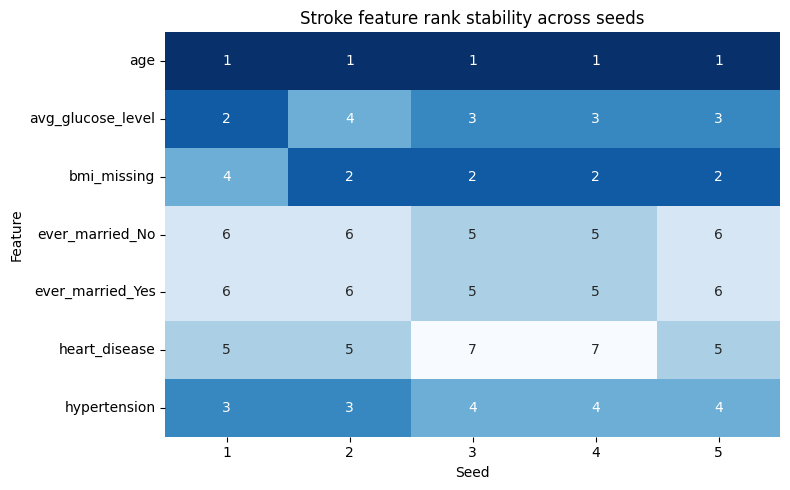

In [ ]:
# -----------------------------
# 10. Stability analysis
# -----------------------------
seeds = [1, 2, 3, 4, 5]
stability_rows = []

for seed in seeds:
    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        X_selected, y,
        test_size=0.2,
        random_state=seed,
        stratify=y
    )

    scaler_s = StandardScaler()
    X_train_s = scaler_s.fit_transform(X_train_s)
    X_test_s = scaler_s.transform(X_test_s)

    X_train_s = pd.DataFrame(X_train_s, columns=feature_names)
    X_test_s = pd.DataFrame(X_test_s, columns=feature_names)

    model_s = LogisticRegression(max_iter=1000)
    model_s.fit(X_train_s, y_train_s)

    perm_s = permutation_importance(
        model_s,
        X_test_s,
        y_test_s,
        n_repeats=10,
        random_state=seed,
        scoring="roc_auc"
    )

    temp = pd.DataFrame({
        "Feature": feature_names,
        "Importance": perm_s.importances_mean,
       "Seed": seed
    })
    stability_rows.append(temp)

stability_df = pd.concat(stability_rows, ignore_index=True)

stability_df["Rank"] = stability_df.groupby("Seed")["Importance"].rank(
    ascending=False,
    method="min"
)

stability_summary = stability_df.groupby("Feature").agg(
    MeanImportance=("Importance", "mean"),
    StdImportance=("Importance", "std"),
    MeanRank=("Rank", "mean"),
    StdRank=("Rank", "std")
).sort_values("MeanRank")

print("\nStability summary")
print(stability_summary.round(4))

rank_pivot = stability_df.pivot(index="Feature", columns="Seed", values="Rank")
print("\nFeature rank by seed")
print(rank_pivot)

plt.figure(figsize=(8, 5))
sns.heatmap(rank_pivot, annot=True, cmap="Blues_r", cbar=False)
plt.title("Stroke feature rank stability across seeds")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "stroke_rank_stability_heatmap.png"), dpi=300)
plt.show()


In [7]:
coef_df.to_csv(os.path.join(out_dir, "stroke_lr_coefficients.csv"), index=False)
perm_df.to_csv(os.path.join(out_dir, "stroke_permutation_importance.csv"), index=False)
shap_imp.to_csv(os.path.join(out_dir, "stroke_shap_importance.csv"), index=False)
rank_compare.to_csv(os.path.join(out_dir, "stroke_corr_vs_shap_rank.csv"), index=False)
rep_cases.to_csv(os.path.join(out_dir, "stroke_representative_cases.csv"))
lime_df.to_csv(os.path.join(out_dir, "stroke_lime_cases.csv"), index=False)
stability_df.to_csv(os.path.join(out_dir, "stroke_stability_raw.csv"), index=False)
stability_summary.to_csv(os.path.join(out_dir, "stroke_stability_summary.csv"))
